In [ ]:
!pip install datasets
!pip install sacrebleu
!pip install unsloth

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 5.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.1/56.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.0/67.0 MB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 85.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 421.9/421.9 kB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 80.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 69.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.2/185.2 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from collections import Counter
from datasets import load_dataset
from tqdm.auto import tqdm
import sacrebleu
import matplotlib.pyplot as plt
from unsloth import FastLanguageModel

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [ ]:
dataset = load_dataset("FIdo-AI/ua-news")
train_data = dataset['train']
test_data = dataset['test']


train.csv:   0%|          | 0.00/324M [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/81.3M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120417 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/30105 [00:00<?, ? examples/s]

In [ ]:
df_view = train_data.select(range(15)).to_pandas()
display(df_view.head(15))

,title,text,tags,target
0,"ВЕРНИДУБ: «Наносимо 25 ударів, 15 у ворота, а ...",Головний тренер солігорського «Шахтаря» Юрій В...,Футбол|Інші новини|Шахтар Солігорськ|Юрій Верн...,спорт
1,"У ""Київстар"" заявляють, що їх обшукала ДФС",Про це на своїй сторінці у Facebook написав пр...,|Київстар|Новини|податкова|ДФС|обшук|,новини
2,В 2016 році 1% найзаможніших людей вперше ста...,Про це повідомляється в доповіді некомерційної...,|багатство|найбагатші люди світу|Новини|бідність|,новини
3,Шакіл О’Ніл продав шикарний маєток у Флориді в...,Легенда НБА Шакіл О’Ніл продав свій маєток у ...,США|Баскетбол|Флорида|Фото,спорт
4,"У «заблокованій» СБУ B2B Jewelry заявили, що п...",Засновник фінансової піраміди B2B Jewelry Мик...,Служба безпеки України (СБУ)|Финансовая пирами...,бізнес
5,На Донеччині зафіксували сьомий випадок корон...,Про це повідомив голова Донецької ОДА Павло Ки...,|Донецька область|COVID-19|Новини|,новини
6,В українських кінотеатрах вперше покажуть філ...,"Творці стрічки ""Поводир"" дають змогу людям із ...",|Кіно|Новини|сліпі|,новини
7,Тематикою новорічного свята на Софійській пло...,Про це на своїй сторінці у Facebook повідомили...,|святкування нового року|Софійська площа|новор...,новини
8,Нардепи від “ЄС” ініціювали розслідування міл...,"Звернення оприлюднив народний депутат України,...",|Львів|Новини|Олег Синютка|Європейська солідар...,політика
9,Facebook запустила сервіс для знайомств в Європі,Американська корпорація Facebook запустила в 3...,Facebook,технології


In [ ]:
example = train_data[0]

print(f"ЗАГОЛОВОК: {example['title']}")
print(f"ТЕГИ: {example['tags']}")
print(f"ТЕКСТ (перші 300 символів): {example['text'][:300]}...")

ЗАГОЛОВОК: ВЕРНИДУБ: «Наносимо 25 ударів, 15 у ворота, а забити не можемо. Сумно»
ТЕГИ: Футбол|Інші новини|Шахтар Солігорськ|Юрій Вернидуб|чемпіонат Білорусі з футболу|Слуцьк
ТЕКСТ (перші 300 символів): Головний тренер солігорського «Шахтаря» Юрій Вернидуб на післяматчевій прес-конференції пояснив, чому його підопічні програли команді «Слуцьк» (1:2): «Такого початку я не пам'ятаю у своєму житті. Але що є, то є. Виправдовуватися я не буду. Якщо команда в тій грі – зі «Смолевичами» – завдає 21 удару,...


In [ ]:
df_view = test_data.select(range(5)).to_pandas()
display(df_view.head(5))

,title,text,tags,target
0,Вілліан загубився в Арсеналі. Два удари за 20 ...,"Арсенал вилетів з Кубка Англії, програвши Саут...",Футбол|Англія|Вілліан|Арсенал Лондон|чемпіонат...,спорт
1,Меркель закликала Путіна вплинути на бойовикі...,Як зазначив офіційний представник кабінету мін...,|Ангела Меркель|Новини|Володимир Путін|,політика
2,Південна Корея досягла згоди з Путіним щодо К...,Про це після зустрічі з президентом Росії Воло...,|КНДР|Росія|Південна Корея|Північна Корея|Нови...,політика
3,Російський рубль оновив антирекорд 2016 року,Курс російського рубля на торгах на Московськ...,Курс рубля|Рубль|Ціни на нафту,бізнес
4,США нададуть $125 млн для Донбасу та прилегли...,Про це повідомив заступник адміністратора і ке...,|допомога|Донбас|Новини|USAID|російська агресія|,політика


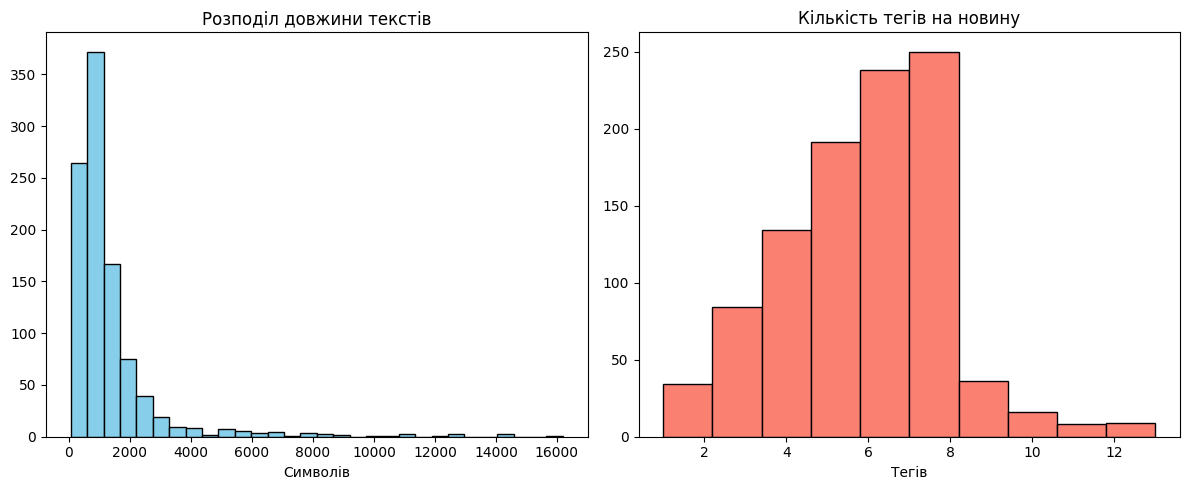

In [ ]:
text_lengths = [len(text) for text in train_data.select(range(1000))['text']]
tag_counts = [len(str(tags).split('|')) for tags in train_data.select(range(1000))['tags']]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(text_lengths, bins=30, color='skyblue', edgecolor='black')
plt.title('Розподіл довжини текстів')
plt.xlabel('Символів')

plt.subplot(1, 2, 2)
plt.hist(tag_counts, bins=10, color='salmon', edgecolor='black')
plt.title('Кількість тегів на новину')
plt.xlabel('Тегів')

plt.tight_layout()
plt.show()

In [ ]:
# 1. ПІДГОТОВКА ДАНИХ ТА МІТОК
print("Підготовка даних та фільтрація тегів...")

def clean_tags(tags_raw):
    if not tags_raw: return []
    return [t.strip().lower() for t in str(tags_raw).split('|') if t.strip()]

# Топ-200 тегів
all_train_tags = [tag for tags in train_data['tags'] for tag in clean_tags(tags)]
top_200_tags = [tag for tag, count in Counter(all_train_tags).most_common(200)]
mlb = MultiLabelBinarizer(classes=top_200_tags)

train_texts = [f"{i['title']} {i['text'][:500]}" for i in train_data]
test_texts = [f"{i['title']} {i['text'][:500]}" for i in test_data]

y_true_test_all = [clean_tags(i['tags']) for i in test_data]
y_true_test_filtered = [[t for t in tags if t in top_200_tags] for tags in y_true_test_all]

# Бінарні матриці для навчання та валідації MLP
y_train_mlp = mlb.fit_transform([[t for t in clean_tags(i['tags']) if t in top_200_tags] for i in train_data])
y_test_mlp = mlb.transform(y_true_test_filtered)

Підготовка даних та фільтрація тегів...


In [ ]:
# 2. ВЕКТОРИЗАЦІЯ (TF-IDF)
print("✨ Векторизація текстів (TF-IDF)...")
vectorizer = TfidfVectorizer(
    max_features=5000,
)
X_train_sparse = vectorizer.fit_transform(train_texts)
X_test_sparse = vectorizer.transform(test_texts)
feature_names = vectorizer.get_feature_names_out()

✨ Векторизація текстів (TF-IDF)...


In [ ]:
print(f"Розмірність матриці тренувальних даних: {X_train_sparse.shape}")
first_doc_vector = X_test_sparse[0].toarray().flatten()
top_keywords = pd.DataFrame({
    'word': feature_names,
    'weight': first_doc_vector
}).sort_values(by='weight', ascending=False).head(10)
print("\nТоп-10 ключових слів для першої тестової новини:")
print(top_keywords[top_keywords['weight'] > 0])

Розмірність матриці тренувальних даних: (120417, 5000)

Топ-10 ключових слів для першої тестової новини:
              word    weight
2255        матчів  0.364724
3452        провів  0.350690
32              20  0.280463
1161           два  0.199951
369       арсеналу  0.175846
2706          ніяк  0.173079
471   бразильський  0.172224
817          воріт  0.171128
688        вилетів  0.168349
4531         форму  0.160137


In [ ]:
# 3. УНІФІКОВАНА ФУНКЦІЯ ОЦІНКИ
def evaluate_model(name, predicted_tags, true_tags):
    f1_scores = []
    chrf_scores = []

    for pred, true in zip(predicted_tags, true_tags):
        p_set, t_set = set(pred), set(true)
        tp = len(p_set.intersection(t_set))
        fp = len(p_set - t_set)
        fn = len(t_set - p_set)

        prec = tp / (tp + fp) if (tp + fp) > 0 else 0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0
        f1_scores.append(f1)

        chrf = sacrebleu.sentence_chrf(" ".join(list(p_set)), [" ".join(list(t_set))])
        chrf_scores.append(chrf.score)

    print(f"\n--- {name} Results ---")
    print(f"Середній F1: {np.mean(f1_scores):.4f}")
    print(f"Середній chrF++: {np.mean(chrf_scores):.2f}")

In [ ]:
# 4. TF-IDF EXTRACTION (BASELILNE)
def get_top_keywords(sparse_matrix, names, top_n=5):
    preds = []
    dense_matrix = sparse_matrix.toarray()
    for i in range(dense_matrix.shape[0]):
        row = dense_matrix[i]
        top_ids = np.argsort(row)[-top_n:][::-1]
        preds.append([names[tid] for tid in top_ids if row[tid] > 0])
    return preds

print("\n🚀 Виконання TF-IDF Baseline...")
pred_tags_tfidf = get_top_keywords(X_test_sparse, feature_names)
evaluate_model("TF-IDF Extraction (Повна)", pred_tags_tfidf, y_true_test_all)
evaluate_model("TF-IDF Extraction (Спрощена)", pred_tags_tfidf, y_true_test_filtered)


🚀 Виконання TF-IDF Baseline...

--- TF-IDF Extraction (Повна) Results ---
Середній F1: 0.0572
Середній chrF++: 17.66

--- TF-IDF Extraction (Спрощена) Results ---
Середній F1: 0.0337
Середній chrF++: 14.25


In [ ]:
display_comparison_table(test_data, pred_tags_tfidf, y_true_test_all)

,Заголовок,Еталон (Ground Truth),Прогноз моделі
0,Вілліан загубився в Арсеналі. Два удари за 20 матчів...,футбол | англія | вілліан | арсенал лондон | чемпіонат англії по футболу | англійська прем'єр-ліга,матчів | провів | 20 | два | арсеналу
1,Меркель закликала Путіна вплинути на бойовиків та навести лад на росі...,ангела меркель | новини | володимир путін,кордоні | російсько | меркель | українському | важлива
2,Південна Корея досягла згоди з Путіним щодо КНДР ...,кндр | росія | південна корея | північна корея | новини | володимир путін,кндр | південної | путіним | кореї | зустрічі
3,Російський рубль оновив антирекорд 2016 року ...,курс рубля | рубль | ціни на нафту,курс | нафти | 80 | 2016 | року
4,США нададуть $125 млн для Донбасу та прилеглих територій ...,допомога | донбас | новини | usaid | російська агресія,млн | можливостей | економічних | впливу | справах
5,Акції Укрзалізниці розмістять на міжнародних біржах — програма дій уря...,укрзалізниця | кабінет міністрів україни | ipo,міжнародних | акції | дій | уряду | на
6,Pinterest блокує пошук контенту за тегами Ukraine і Ukrainian...,скандал | техно | інтернет | новини техно,ukraine | рішення | 24 | компанії | за
7,"""Сенсу немає мені слухати"": Трамп про запис убивства Хашоггі ...",вбивство хашоггі | вбивство журналіста | новини | джамал хашоггі,запис | трамп | мені | немає | білого
8,ВІДЕО ДНЯ. Як Берінчик захистив титул WBO International...,бокс | wbo | денис берінчик | бровари | патрисіо лопес морено | відео бою | денис берінчик - патрісіо лопес морено,120 | international | wbo | ко | легкій
9,Новий клуб Балотеллі хоче підписати ще одного зіркового гравця...,футбол | туреччина | адана демірспор | давід луіс | арсенал лондон,клуб | турецький | підписала | бразильський | агента


In [ ]:
# 5. MLP CLASSIFICATION
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Тензори
X_train_tensor = torch.tensor(X_train_sparse.toarray(), dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_mlp, dtype=torch.float32)
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=128, shuffle=True)

# Дані для валідації в реальному часі
X_val_tensor = torch.tensor(X_test_sparse.toarray(), dtype=torch.float32).to(device)
y_val_tensor = torch.tensor(y_test_mlp, dtype=torch.float32).to(device)

class TagMLP(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_size, 1024), nn.ReLU(), nn.BatchNorm1d(1024), nn.Dropout(0.4),
            nn.Linear(1024, 512), nn.ReLU(),
            nn.Linear(512, num_classes)
        )
    def forward(self, x): return self.model(x)

def fast_f1(outputs, labels):
    preds = (torch.sigmoid(outputs) > 0.5).float()
    tp = (preds * labels).sum(dim=1)
    fp = (preds * (1 - labels)).sum(dim=1)
    fn = ((1 - preds) * labels).sum(dim=1)
    return (2 * tp / (2 * tp + fp + fn + 1e-8)).mean().item()

In [ ]:
model_mlp = TagMLP(5000, 200).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_mlp.parameters(), lr=0.001)

history = {'train_loss': [], 'train_f1': [], 'val_f1': []}
epochs = 10

print(f"\nПочинаємо навчання MLP на {device}...")
for epoch in range(epochs):
    model_mlp.train()
    running_loss, train_f1_batch = 0.0, []

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
    for inputs, labels in pbar:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_mlp(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        train_f1_batch.append(fast_f1(outputs, labels))
        pbar.set_postfix({'loss': f"{loss.item():.4f}", 'f1': f"{train_f1_batch[-1]:.4f}"})

    # Валідація
    model_mlp.eval()
    with torch.no_grad():
        val_outputs = model_mlp(X_val_tensor)
        current_val_f1 = fast_f1(val_outputs, y_val_tensor)

    epoch_loss = running_loss / len(train_loader)
    epoch_train_f1 = np.mean(train_f1_batch)
    history['train_loss'].append(epoch_loss)
    history['train_f1'].append(epoch_train_f1)
    history['val_f1'].append(current_val_f1)

    print(f"Епоха {epoch+1} завершена: Loss = {epoch_loss:.4f} | Train F1 = {epoch_train_f1:.4f}")


Починаємо навчання MLP на cuda...


Epoch 1/10:   0%|          | 0/941 [00:00<?, ?it/s]

Епоха 1 завершена: Loss = 0.0242 | Train F1 = 0.5970


Epoch 2/10:   0%|          | 0/941 [00:00<?, ?it/s]

Епоха 2 завершена: Loss = 0.0131 | Train F1 = 0.6836


...

Епоха 8 завершена: Loss = 0.0044 | Train F1 = 0.8359


Epoch 9/10:   0%|          | 0/941 [00:00<?, ?it/s]

Епоха 9 завершена: Loss = 0.0040 | Train F1 = 0.8438


Epoch 10/10:   0%|          | 0/941 [00:00<?, ?it/s]

Епоха 10 завершена: Loss = 0.0037 | Train F1 = 0.8502


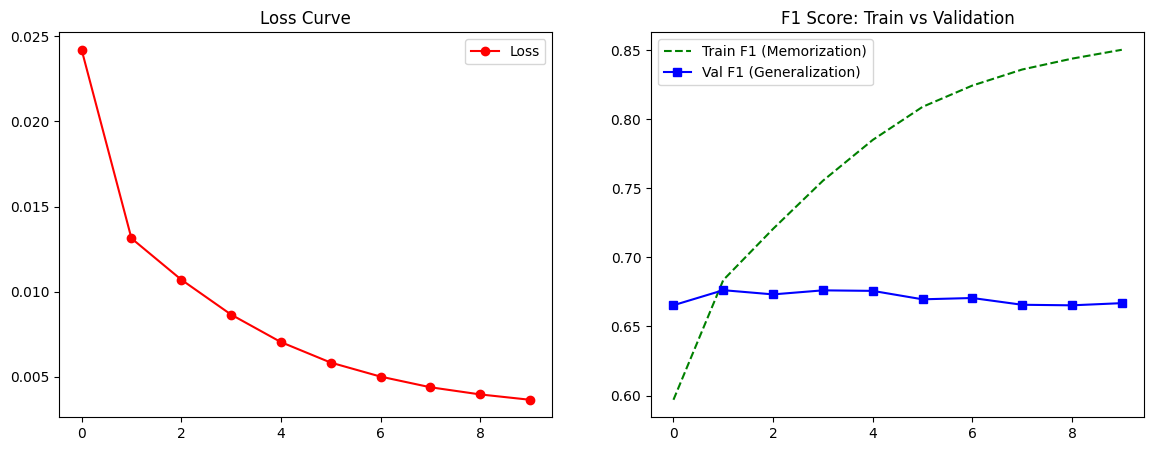


Фінальна оцінка моделі на тестовій вибірці...

--- MLP Classification (Повна) Results ---
Середній F1: 0.4335
Середній chrF++: 27.23

--- MLP Classification (Спрощена) Results ---
Середній F1: 0.6669
Середній chrF++: 61.56


In [ ]:
# 6. ВІЗУАЛІЗАЦІЯ ТА ФІНАЛЬНА ОЦІНКА

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], 'r-o', label='Loss')
plt.title('Loss Curve')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['train_f1'], 'g--', label='Train F1 (Memorization)')
plt.plot(history['val_f1'], 'b-s', label='Val F1 (Generalization)')
plt.title('F1 Score: Train vs Validation')
plt.legend()
plt.show()

print("\nФінальна оцінка моделі на тестовій вибірці...")
model_mlp.eval()
with torch.no_grad():
    outputs = model_mlp(X_val_tensor)
    preds_bin = (torch.sigmoid(outputs) > 0.5).cpu().numpy()

pred_tags_mlp = mlb.inverse_transform(preds_bin)
evaluate_model("MLP Classification (Повна)", pred_tags_mlp, y_true_test_all)
evaluate_model("MLP Classification (Спрощена)", pred_tags_mlp, y_true_test_filtered)

In [ ]:
display_comparison_table(test_data, pred_tags_mlp, y_true_test_all)

,Заголовок,Еталон (Ground Truth),Прогноз моделі
0,Вілліан загубився в Арсеналі. Два удари за 20 матчів...,футбол | англія | вілліан | арсенал лондон | чемпіонат англії по футболу | англійська прем'єр-ліга,футбол | англія | челсі
1,Меркель закликала Путіна вплинути на бойовиків та навести лад на росі...,ангела меркель | новини | володимир путін,новини
2,Південна Корея досягла згоди з Путіним щодо КНДР ...,кндр | росія | південна корея | північна корея | новини | володимир путін,новини | володимир путін
3,Російський рубль оновив антирекорд 2016 року ...,курс рубля | рубль | ціни на нафту,
4,США нададуть $125 млн для Донбасу та прилеглих територій ...,допомога | донбас | новини | usaid | російська агресія,новини | росія | донбас
5,Акції Укрзалізниці розмістять на міжнародних біржах — програма дій уря...,укрзалізниця | кабінет міністрів україни | ipo,
6,Pinterest блокує пошук контенту за тегами Ukraine і Ukrainian...,скандал | техно | інтернет | новини техно,техно | новини техно | інтернет
7,"""Сенсу немає мені слухати"": Трамп про запис убивства Хашоггі ...",вбивство хашоггі | вбивство журналіста | новини | джамал хашоггі,новини | дональд трамп
8,ВІДЕО ДНЯ. Як Берінчик захистив титул WBO International...,бокс | wbo | денис берінчик | бровари | патрисіо лопес морено | відео бою | денис берінчик - патрісіо лопес морено,бокс
9,Новий клуб Балотеллі хоче підписати ще одного зіркового гравця...,футбол | туреччина | адана демірспор | давід луіс | арсенал лондон,футбол | трансфери | італія


In [ ]:
#7 Zero-Shot LLM
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/meta-llama-3.1-8b-instruct-bnb-4bit",
    max_seq_length = 2048,
    load_in_4bit = True,
)
FastLanguageModel.for_inference(model)

test_subset = dataset['test'].select(range(1000))

==((====))==  Unsloth 2026.4.8: Fast Llama patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Unsloth: Will load unsloth/meta-llama-3.1-8b-instruct-bnb-4bit as a legacy tokenizer.


In [ ]:
def get_prompt(title, text):
    messages = [
        {"role": "system", "content": "Ти — помічник, який виділяє теги для новин. Пиши ТІЛЬКИ теги через |. Не додавай жодних пояснень."},
        {"role": "user", "content": f"Заголовок: {title}\nТекст: {text[:800]}\n\nВиділи 3-5 тегів:"},
    ]
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)

In [ ]:
y_true_llm = [clean_tags(item['tags']) for item in test_subset]

In [ ]:
tokenizer.padding_side = "left"
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

batch_size = 16
test_subset = dataset['test'].select(range(1000))
llm_zero_shot_preds = []

print(f"Запуск пакетної генерації (Batch Size: {batch_size})...")

for i in tqdm(range(0, len(test_subset), batch_size)):
    batch = test_subset[i : i + batch_size]
    prompts = [get_prompt(t, txt) for t, txt in zip(batch['title'], batch['text'])]

    inputs = tokenizer(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=1500
    ).to("cuda")

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=40,
            use_cache=True,
            pad_token_id=tokenizer.eos_token_id,
            do_sample=False
        )

    generated_tokens = outputs[:, inputs.input_ids.shape[1]:]

    decoded_responses = tokenizer.batch_decode(generated_tokens, skip_special_tokens=True)

    if i == 0:
        print("\nПЕРЕВІРКА ПЕРШОГО БАТЧУ:")
        for idx in range(3):
            print(f"[{idx}] Вихід моделі: '{decoded_responses[idx].strip()}'")
            print("-" * 20)

    for res in decoded_responses:
        llm_zero_shot_preds.append(clean_tags(res.strip()))
evaluate_model("LLM Zero-shot (Fast Batch)", llm_zero_shot_preds, y_true_llm)

Запуск пакетної генерації (Batch Size: 16)...


  0%|          | 0/63 [00:00<?, ?it/s]

Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



ПЕРЕВІРКА ПЕРШОГО БАТЧУ:
[0] Вихід моделі: 'Кубок Англії | Прем'єр-ліга | Вілліан'
--------------------
[1] Вихід моделі: 'Меркель | Путін | ОБСЄ'
--------------------
[2] Вихід моделі: 'Північна Корея | Південна Корея | Володимир Путін | КНДР'
--------------------


Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene


--- LLM Zero-shot (Fast Batch) Results ---
Середній F1: 0.2106
Середній chrF++: 30.42


In [ ]:
def get_model_predictions(model, data_subset, batch_size=8):
    model.eval()
    all_preds = []
    print(f"🚀 Генерація для {len(data_subset)} прикладів...")

    for i in tqdm(range(0, len(data_subset), batch_size)):
        batch = data_subset[i : i + batch_size]
        prompts = [get_prompt(t, txt) for t, txt in zip(batch['title'], batch['text'])]

        inputs = tokenizer(
            prompts, return_tensors="pt", padding=True, truncation=True, max_length=1500
        ).to("cuda")

        with torch.no_grad():
            outputs = model.generate(
                **inputs, max_new_tokens=40, use_cache=True,
                pad_token_id=tokenizer.eos_token_id, do_sample=False
            )

        generated_tokens = outputs[:, inputs.input_ids.shape[1]:]
        decoded = tokenizer.batch_decode(generated_tokens, skip_special_tokens=True)

        for res in decoded:
            all_preds.append(clean_tags(res.strip()))

    return all_preds

In [ ]:
def plot_tag_distribution(pred_tags, title="Топ-15 згенерованих тегів"):
    all_tags = [tag for sublist in pred_tags for tag in sublist]
    tag_counts = Counter(all_tags).most_common(15)

    names, values = zip(*tag_counts)

    plt.figure(figsize=(10, 6))
    plt.barh(names, values, color='skyblue')
    plt.gca().invert_yaxis()
    plt.title(title)
    plt.xlabel("Кількість згадок")
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.show()

In [ ]:
def display_comparison_table(data_subset, pred_tags, true_tags, n=10):
    demo_data = []
    for i in range(min(n, len(data_subset))):
        demo_data.append({
            "Заголовок": data_subset[i]['title'][:70] + "...",
            "Еталон (Ground Truth)": " | ".join(true_tags[i]),
            "Прогноз моделі": " | ".join(pred_tags[i])
        })

    df = pd.DataFrame(demo_data)
    pd.set_option('display.max_colwidth', None)
    display(df)

In [ ]:
display_comparison_table(test_subset, llm_zero_shot_preds, y_true_llm, 20)

,Заголовок,Еталон (Ground Truth),Прогноз моделі
0,Вілліан загубився в Арсеналі. Два удари за 20 матчів...,футбол | англія | вілліан | арсенал лондон | чемпіонат англії по футболу | англійська прем'єр-ліга,кубок англії | прем'єр-ліга | вілліан
1,Меркель закликала Путіна вплинути на бойовиків та навести лад на росі...,ангела меркель | новини | володимир путін,меркель | путін | обсє
2,Південна Корея досягла згоди з Путіним щодо КНДР ...,кндр | росія | південна корея | північна корея | новини | володимир путін,північна корея | південна корея | володимир путін | кндр
3,Російський рубль оновив антирекорд 2016 року ...,курс рубля | рубль | ціни на нафту,російський рубль | економіка | фінанси | нафта | світові фондові ринки | опек | цінової війна | фінансові р
4,США нададуть $125 млн для Донбасу та прилеглих територій ...,допомога | донбас | новини | usaid | російська агресія,сша | донбас | сшааід | україна
5,Акції Укрзалізниці розмістять на міжнародних біржах — програма дій уря...,укрзалізниця | кабінет міністрів україни | ipo,уряд | залізничні послуги | залізничні перевезення | залізнична інфраструктура
6,Pinterest блокує пошук контенту за тегами Ukraine і Ukrainian...,скандал | техно | інтернет | новини техно,пошук | пропагандистський | російський | україна | українська | крим | спільнота | pinterest | блокування
7,"""Сенсу немає мені слухати"": Трамп про запис убивства Хашоггі ...",вбивство хашоггі | вбивство журналіста | новини | джамал хашоггі,трамп | хашоггі | саудівська аравія | сша
8,ВІДЕО ДНЯ. Як Берінчик захистив титул WBO International...,бокс | wbo | денис берінчик | бровари | патрисіо лопес морено | відео бою | денис берінчик - патрісіо лопес морено,відео дня | бокс | спорт | український боксер | титул wbo international | денис берінчик | патрісіо л
9,Новий клуб Балотеллі хоче підписати ще одного зіркового гравця...,футбол | туреччина | адана демірспор | давід луіс | арсенал лондон,новий клуб | балотеллі | футбол | трансфери | давід луїс | млс | футбольний клуб адана демірспор


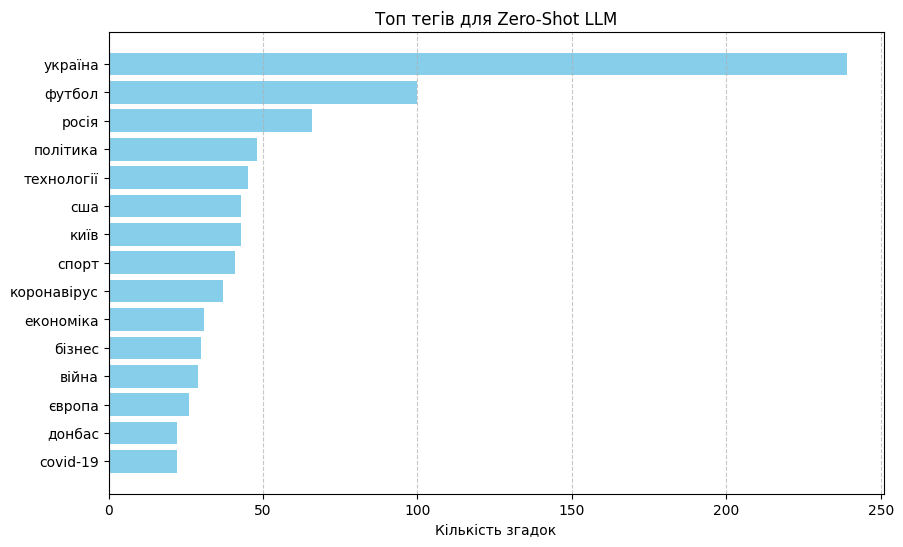

In [ ]:
plot_tag_distribution(llm_zero_shot_preds, title="Топ тегів для Zero-Shot LLM")

In [ ]:
import gc
gc.collect()
torch.cuda.empty_cache()

In [ ]:
from unsloth import FastLanguageModel
from trl import SFTTrainer
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported

#8.LORA

model = FastLanguageModel.get_peft_model(
    model,
    r = 16,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj",],
    lora_alpha = 16,
    lora_dropout = 0,
    bias = "none",
    use_gradient_checkpointing = "unsloth",
    random_state = 3407,
)

def formatting_prompts_func(examples):
    instructions = []
    for title, text, tags in zip(examples["title"], examples["text"], examples["tags"]):
        msg = f"<|begin_of_text|><|start_header_id|>system<|end_header_id|>\n" \
              f"Ти — помічник, який виділяє теги для новин. Пиши ТІЛЬКИ теги через |.<|eot_id|>" \
              f"<|start_header_id|>user<|end_header_id|>\n" \
              f"Заголовок: {title}\nТекст: {text[:800]}\n\nВиділи 3-5 тегів:<|eot_id|>" \
              f"<|start_header_id|>assistant<|end_header_id|>\n" \
              f"{tags}<|eot_id|>"
        instructions.append(msg)
    return { "text" : instructions }

train_subset_lora = dataset['train'].select(range(5000))
train_dataset = train_subset_lora.map(formatting_prompts_func, batched = True)

eval_subset_lora = dataset['test'].select(range(500))
eval_dataset = eval_subset_lora.map(formatting_prompts_func, batched = True)


trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = train_dataset,
    eval_dataset = eval_dataset,
    dataset_text_field = "text",
    max_seq_length = 2048,
    args = TrainingArguments(
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,
        warmup_steps = 5,
        max_steps = 80,
        learning_rate = 2e-4,
        fp16 = not is_bfloat16_supported(),
        bf16 = is_bfloat16_supported(),

        logging_strategy = "steps",
        logging_steps = 1,
        eval_strategy = "steps",
        eval_steps = 10,

        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
        report_to = "none",
    ),
)

print("Починаємо донавчання LoRA з моніторингом...")
trainer_stats = trainer.train()

Unsloth: Already have LoRA adapters! We shall skip this step.


Починаємо донавчання LoRA з моніторингом...


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 5,000 | Num Epochs = 1 | Total steps = 80
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 41,943,040 of 8,072,204,288 (0.52% trained)


Step,Training Loss,Validation Loss
10,1.731797,1.663401
20,1.674354,1.545884
30,1.311610,1.493928
40,1.603135,1.460690
50,1.495185,1.438683
60,1.306567,1.425601
70,1.446011,1.420450
80,1.542420,1.418393


/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:172: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API 

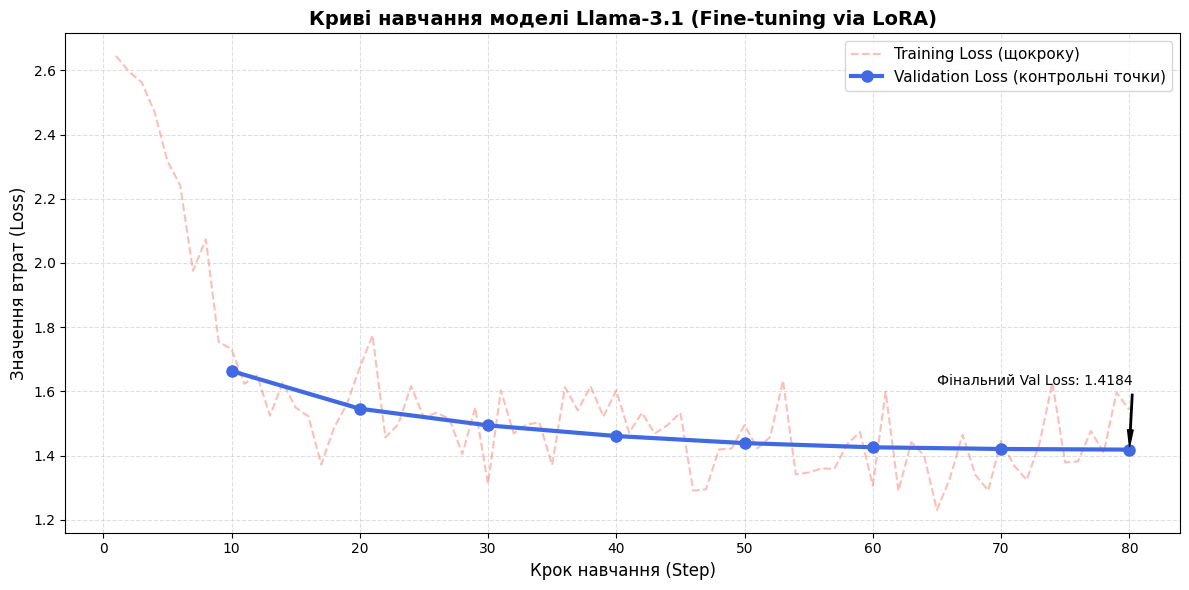

In [ ]:
import matplotlib.pyplot as plt

history = trainer.state.log_history

train_loss = [x['loss'] for x in history if 'loss' in x]
train_steps = [x['step'] for x in history if 'loss' in x]

val_loss = [x['eval_loss'] for x in history if 'eval_loss' in x]
val_steps = [x['step'] for x in history if 'eval_loss' in x]

plt.figure(figsize=(12, 6))

plt.plot(train_steps, train_loss, label='Training Loss (щокроку)', color='salmon', alpha=0.5, linestyle='--')

plt.plot(val_steps, val_loss, label='Validation Loss (контрольні точки)', color='royalblue', linewidth=3, marker='o', markersize=8)

plt.title('Криві навчання моделі Llama-3.1 (Fine-tuning via LoRA)', fontsize=14, fontweight='bold')
plt.xlabel('Крок навчання (Step)', fontsize=12)
plt.ylabel('Значення втрат (Loss)', fontsize=12)
plt.grid(True, which='both', linestyle='--', alpha=0.4)
plt.legend(fontsize=11)

if val_loss:
    plt.annotate(f'Фінальний Val Loss: {val_loss[-1]:.4f}',
                 xy=(val_steps[-1], val_loss[-1]),
                 xytext=(val_steps[-1]-15, val_loss[-1]+0.2),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=4))

plt.tight_layout()
plt.show()

In [ ]:
from unsloth import FastLanguageModel

FastLanguageModel.for_inference(model)

lora_predictions = get_model_predictions(model, test_subset, batch_size=16)

🚀 Генерація для 1000 прикладів...


  0%|          | 0/63 [00:00<?, ?it/s]

Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12


АБЛИЦЯ ПОРІВНЯННЯ (Еталон vs LoRA):


NameError: name 'y_true_llm' is not defined


АБЛИЦЯ ПОРІВНЯННЯ (Еталон vs LoRA):


,Заголовок,Еталон (Ground Truth),Прогноз моделі
0,Вілліан загубився в Арсеналі. Два удари за 20 матчів...,футбол | англія | вілліан | арсенал лондон | чемпіонат англії по футболу | англійська прем'єр-ліга,футбол | вілліан | кубок англії | арсенал | саутгемптон
1,Меркель закликала Путіна вплинути на бойовиків та навести лад на росі...,ангела меркель | новини | володимир путін,німеччина | путін | меркель | новини
2,Південна Корея досягла згоди з Путіним щодо КНДР ...,кндр | росія | південна корея | північна корея | новини | володимир путін,північна корея | новини | володимир путін | мун чже ін
3,Російський рубль оновив антирекорд 2016 року ...,курс рубля | рубль | ціни на нафту,росія | рубль | новини
4,США нададуть $125 млн для Донбасу та прилеглих територій ...,допомога | донбас | новини | usaid | російська агресія,сша | донбас | новини | usaid
5,Акції Укрзалізниці розмістять на міжнародних біржах — програма дій уря...,укрзалізниця | кабінет міністрів україни | ipo,укрзалізниця | біржа | новини
6,Pinterest блокує пошук контенту за тегами Ukraine і Ukrainian...,скандал | техно | інтернет | новини техно,pinterest | новини | техно
7,"""Сенсу немає мені слухати"": Трамп про запис убивства Хашоггі ...",вбивство хашоггі | вбивство журналіста | новини | джамал хашоггі,дональд трамп | новини | новини сша
8,ВІДЕО ДНЯ. Як Берінчик захистив титул WBO International...,бокс | wbo | денис берінчик | бровари | патрисіо лопес морено | відео бою | денис берінчик - патрісіо лопес морено,бокс | денис берінчик | виділи 3-5 тегів | виділи 3-5 тегів | виділи 3-5 т
9,Новий клуб Балотеллі хоче підписати ще одного зіркового гравця...,футбол | туреччина | адана демірспор | давід луіс | арсенал лондон,футбол | давід луїс | адана демірспор | млс | маріо балотеллі | новини | новини фут



РОЗПОДІЛ ТЕГІВ ПІСЛЯ ДОНАВЧАННЯ:


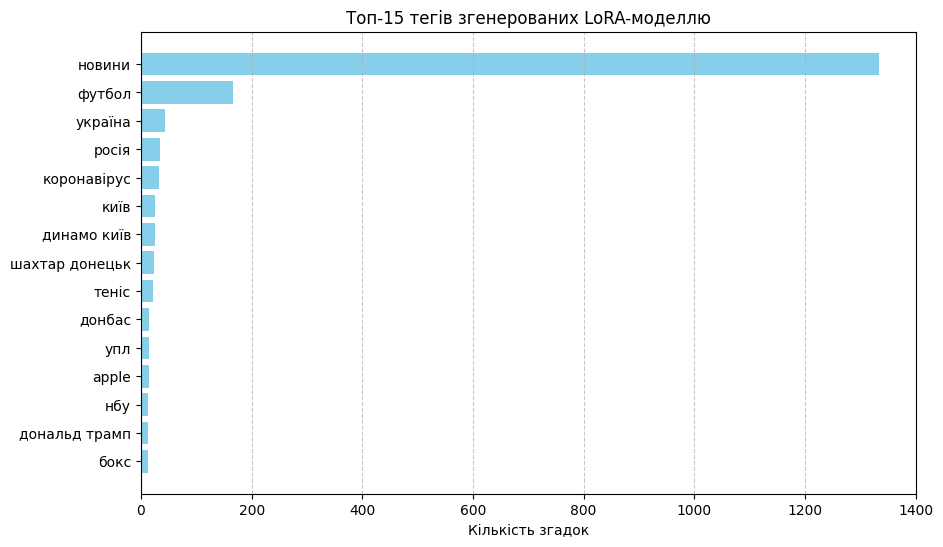


ФІНАЛЬНІ МЕТРИКИ ЯКОСТІ:

--- Llama-3.1 + LoRA (Final) Results ---
Середній F1: 0.4348
Середній chrF++: 37.24


In [ ]:
print("\nАБЛИЦЯ ПОРІВНЯННЯ (Еталон vs LoRA):")
display_comparison_table(test_subset, lora_predictions, y_true_llm, n=10)

print("\nРОЗПОДІЛ ТЕГІВ ПІСЛЯ ДОНАВЧАННЯ:")
plot_tag_distribution(lora_predictions, title="Топ-15 тегів згенерованих LoRA-моделлю")

print("\nФІНАЛЬНІ МЕТРИКИ ЯКОСТІ:")
evaluate_model("Llama-3.1 + LoRA (Final)", lora_predictions, y_true_llm)